# Robustness Test: Phishing Email Models on a New Dataset (local GPU)

The models were trained on Kaggle "Phishing Emails" (Phishing_Email.csv). Here we test them, **without retraining**, on a different dataset:
Kaggle "Phishing and Legitimate Emails Dataset" (kuladeep19).

Question: do the models still work on emails from a different source, or did they only learn the first dataset?

| Model | Input | Needs |
|---|---|---|
| A. TF-IDF + LogReg | words | `A_tfidf_logreg.joblib` |
| B. Paper-literal | frozen BERT pooled output | `B_paper_literal_head.pt` + pretrained BERT |
| B-Ablation. Plain MLP | frozen BERT pooled output | `B_ablation_mlp_head.pt` + pretrained BERT |
| D. Paper-literal + MGO head | frozen BERT pooled output | `D_mgo_tuned_head.pt` + pretrained BERT |
| C. Corrected, fine-tuned | full BERT, 128 tokens | `C_corrected_finetuned_full.pt` |

Any model whose file is missing is skipped.

## Folder layout

```
this_notebook.ipynb
phishing_artifacts/          (same folder as the explainability notebook)
    Phishing_Email.csv
    A_tfidf_logreg.joblib
    B_paper_literal_head.pt
    B_ablation_mlp_head.pt
    D_mgo_tuned_head.pt
    C_corrected_finetuned_full.pt
    config_and_versions.json  (optional)
    tokenizer/                (optional)
new_dataset/
    phishing_legit_dataset_KD_10000.csv
```

Same environment as the explainability notebook (`xai-env`). B, B-Ablation and D need the pretrained `bert-base-uncased` weights. They download once (about 440 MB) and are cached after that.

## What the notebook does
1. Loads the new dataset and finds the text and label columns.
2. Removes emails that also appear in the training dataset, so the test is fair.
3. Runs every model on the original test set and on the new dataset.
4. Compares accuracy, precision, recall, F1 and ROC-AUC, with 95% confidence intervals.
5. Checks whether a lower score comes from bad ranking or only from a shifted threshold.
6. Saves tables and grayscale charts to `robustness_outputs/`.

## Step 1: Setup

In [4]:
import os
# Stop transformers from importing TensorFlow / JAX (a broken TF install crashes the import)
os.environ["USE_TF"] = "0"; os.environ["TRANSFORMERS_NO_TF"] = "1"
os.environ["USE_TORCH"] = "1"; os.environ["USE_FLAX"] = "0"; os.environ["USE_JAX"] = "0"

import re, glob, json, random, time, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)
import joblib
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")

CFG = {"bert_name": "bert-base-uncased", "max_len": 128, "n_heads": 8, "cnn_filters": 128,
       "cnn_kernel": 5, "gru_units": 64, "dropout": 0.3, "test_size": 0.15, "val_size": 0.15}

ART = os.path.abspath("phishing_artifacts")     # trained models + original dataset
NEW = os.path.abspath("new_dataset")            # folder with the new Kaggle csv
OUT = os.path.abspath("robustness_outputs")
os.makedirs(OUT, exist_ok=True)

MAX_EVAL = None      # set e.g. 5000 to test on a stratified sample (faster). None = all emails
BATCH    = 32        # lower to 16 if you get "CUDA out of memory"

def maybe(name):
    p = os.path.join(ART, name)
    return p if os.path.exists(p) else None

CFG_PATH = maybe("config_and_versions.json")
MGO_HP = None
if CFG_PATH:
    saved = json.load(open(CFG_PATH))
    CFG.update({k: v for k, v in saved.get("cfg", {}).items() if k in CFG})
    MGO_HP = saved.get("mgo_best_hp")
print("CFG:", CFG)
print("MGO settings:", MGO_HP)

from transformers import AutoTokenizer
TOK_DIR = maybe("tokenizer")
tokenizer = AutoTokenizer.from_pretrained(TOK_DIR or CFG["bert_name"])

Device: cuda | NVIDIA GeForce RTX 3050 6GB Laptop GPU
CFG: {'bert_name': 'bert-base-uncased', 'max_len': 128, 'n_heads': 8, 'cnn_filters': 128, 'cnn_kernel': 5, 'gru_units': 64, 'dropout': 0.3, 'test_size': 0.15, 'val_size': 0.15}
MGO settings: {'gru_units': 256, 'dropout': 0.16576186748945815, 'lr': 0.00013801946767569965}


## Step 2: Original test set (same cleaning, split and seed as training)

In [5]:
def clean(df, text_col, label_series):
    df = df.copy()
    df["text"] = df[text_col]
    df["label"] = label_series
    df = df.dropna(subset=["text", "label"])
    df["text"] = df["text"].astype(str)
    df = df[~df["text"].str.strip().str.lower().isin(["", "empty", "nan", "none"])]
    df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)
    df["label"] = df["label"].astype(int)
    return df[["text", "label"]]

ORIG = pd.read_csv(os.path.join(ART, "Phishing_Email.csv"))
o_text = [c for c in ORIG.columns if "text" in c.lower()][0]
o_lab  = [c for c in ORIG.columns if "type" in c.lower() or "label" in c.lower()][0]
orig = clean(ORIG, o_text, ORIG[o_lab].apply(lambda v: 1 if "phish" in str(v).lower() else 0))

X, y = orig["text"].values, orig["label"].values
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=CFG["test_size"], stratify=y, random_state=SEED)
print(f"Original dataset after cleaning: {len(orig)} | test set: {len(X_test)} ({y_test.mean():.1%} phishing)")

Original dataset after cleaning: 17535 | test set: 2631 (37.4% phishing)


## Step 3: Load the new dataset

The column names are detected automatically. **Check the printout.** If the guess is wrong, set `TEXT_COL` / `LABEL_COL` by hand and re-run this cell.

In [6]:
csvs = sorted(glob.glob(os.path.join(NEW, "*.csv")))
assert csvs, f"No csv found in {NEW}"
NEW_FILE = "phishing_legit_dataset_KD_10000.csv"     # kuladeep19 dataset
NEW_PATH = os.path.join(NEW, NEW_FILE) if os.path.exists(os.path.join(NEW, NEW_FILE)) else max(csvs, key=os.path.getsize)
print("Files found:", [os.path.basename(c) for c in csvs], "| using:", os.path.basename(NEW_PATH))
RAW = pd.read_csv(NEW_PATH, encoding_errors="ignore", low_memory=False)
print("Shape:", RAW.shape)
print("Columns:", list(RAW.columns))
display(RAW.head(3))

# kuladeep19 dataset: only "text" and "label" are used as model input.
# phishing_type / severity / confidence are annotations about the label, so they are NOT fed to the models
# (that would leak the answer). phishing_type and severity are only used later to break results down.
TEXT_COL  = "text"   # set to None to auto-detect for a different dataset
LABEL_COL = "label"
TEXT_COL  = TEXT_COL  if TEXT_COL  in RAW.columns else None
LABEL_COL = LABEL_COL if LABEL_COL in RAW.columns else None
COMBINE_SUBJECT = False   # True = put the subject in front of the body (training data was mostly body only)

def guess_text_col(df):
    names = ["email text", "text", "body", "email_body", "email", "content", "message", "mail"]
    lower = {c.lower(): c for c in df.columns}
    for n in names:
        if n in lower: return lower[n]
    obj = [c for c in df.columns if df[c].dtype == object]
    return max(obj, key=lambda c: df[c].astype(str).str.len().mean())

def guess_label_col(df, text_col):
    for c in df.columns:
        if c != text_col and any(k in c.lower() for k in ["label", "type", "class", "target", "phish", "is_"]):
            if df[c].nunique() <= 10: return c
    small = [c for c in df.columns if c != text_col and df[c].nunique() == 2]
    return small[0]

TEXT_COL  = TEXT_COL  or guess_text_col(RAW)
LABEL_COL = LABEL_COL or guess_label_col(RAW, TEXT_COL)
print(f"\nText column : {TEXT_COL!r}")
print(f"Label column: {LABEL_COL!r}")
print("Label values:\n", RAW[LABEL_COL].value_counts(dropna=False).head(10))
EXTRA_COLS = [c for c in ["phishing_type", "severity"] if c in RAW.columns]
print("Kept aside for the breakdown only (not model input):", EXTRA_COLS)
print("Ignored:", [c for c in RAW.columns if c not in [TEXT_COL, LABEL_COL] + EXTRA_COLS])

Files found: ['phishing_legit_dataset_KD_10000.csv'] | using: phishing_legit_dataset_KD_10000.csv
Shape: (10000, 5)
Columns: ['text', 'label', 'phishing_type', 'severity', 'confidence']


,text,label,phishing_type,severity,confidence
0,Subject: Office maintenance\n\nThanks for your...,0,legitimate,low,0.95
1,"Hello, your profile has been locked. Use the s...",1,credential_harvesting,high,0.89
2,"Hi there, congratulations! You are the winner ...",1,financial_scam,medium,0.69



Text column : 'text'
Label column: 'label'
Label values:
 label
1    6000
0    4000
Name: count, dtype: int64
Kept aside for the breakdown only (not model input): ['phishing_type', 'severity']
Ignored: ['confidence']


In [7]:
POS = {"1", "1.0", "true", "yes", "phishing", "phish", "phishing email", "spam", "malicious", "fraud", "scam"}
NEG = {"0", "0.0", "false", "no", "legitimate", "legit", "safe", "safe email", "ham", "benign", "normal", "not phishing"}

def to_label(v):
    s = str(v).strip().lower()
    if s in POS: return 1
    if s in NEG: return 0
    if s.startswith("not ") or "legit" in s or "safe" in s or "benign" in s: return 0
    if "phish" in s or "spam" in s or "malic" in s or "fraud" in s: return 1
    return np.nan

text_series = RAW[TEXT_COL].astype(str)
subj = [c for c in RAW.columns if "subject" in c.lower()]
if COMBINE_SUBJECT and subj:
    text_series = RAW[subj[0]].fillna("").astype(str) + " " + text_series
RAW["_text"] = text_series

labels = RAW[LABEL_COL].apply(to_label)
unmapped = RAW.loc[labels.isna(), LABEL_COL].value_counts().head(5)
if len(unmapped):
    print("WARNING: these label values were not mapped and will be dropped:\n", unmapped)
print("Label mapping check (raw value -> 0/1):")
print(pd.DataFrame({"raw": RAW[LABEL_COL], "mapped": labels}).drop_duplicates().head(10).to_string(index=False))

new = clean(RAW, "_text", labels)
print(f"\nNew dataset after cleaning: {len(new)} emails | phishing {new.label.mean():.1%}")

Label mapping check (raw value -> 0/1):
 raw  mapped
   0       0
   1       1

New dataset after cleaning: 9956 emails | phishing 60.3%


## Step 4: Remove overlap with the training data

Many public phishing datasets reuse the same sources (Enron, Nazario, SpamAssassin). If an email from the new dataset was already in the training data, the model has seen it, and the test is not fair.
We remove exact matches, and near matches (same first 200 characters after removing spaces and case).

In [8]:
def norm(t):
    return re.sub(r"\s+", " ", str(t).lower()).strip()

orig_full = set(orig["text"].map(norm))
orig_head = set(orig["text"].map(lambda t: norm(t)[:200]))
new_norm = new["text"].map(norm)
exact = new_norm.isin(orig_full)
near  = new_norm.map(lambda t: t[:200]).isin(orig_head) & ~exact
print(f"Exact overlap with training dataset: {exact.sum()} emails")
print(f"Near overlap (same first 200 chars): {near.sum()} emails")
new_clean = new[~(exact | near)].reset_index(drop=True)
print(f"Kept for testing: {len(new_clean)} emails | phishing {new_clean.label.mean():.1%}")

if MAX_EVAL and len(new_clean) > MAX_EVAL:
    new_clean, _ = train_test_split(new_clean, train_size=MAX_EVAL, stratify=new_clean.label, random_state=SEED)
    new_clean = new_clean.reset_index(drop=True)
    print(f"Sampled {len(new_clean)} emails (MAX_EVAL)")

X_new, y_new = new_clean["text"].values, new_clean["label"].values
OVERLAP = {"new_after_cleaning": len(new), "exact_overlap": int(exact.sum()),
           "near_overlap": int(near.sum()), "kept": len(new_clean)}

Exact overlap with training dataset: 0 emails
Near overlap (same first 200 chars): 0 emails
Kept for testing: 9956 emails | phishing 60.3%


## Step 5: How different is the new data?

If the emails are much longer, more of the text is cut off at 128 tokens, which hurts the BERT models.

In [9]:
def length_stats(texts, name):
    words = np.array([len(str(t).split()) for t in texts])
    toks = np.array([len(tokenizer(str(t), truncation=False, add_special_tokens=True)["input_ids"])
                     for t in texts[:3000]])
    return {"dataset": name, "emails": len(texts), "median_words": int(np.median(words)),
            "mean_words": int(words.mean()), "cut_at_128_tokens_%": round((toks > CFG["max_len"]).mean() * 100, 1)}

LEN = pd.DataFrame([length_stats(X_test, "Original test"), length_stats(X_new, "New dataset")])
print(LEN.to_string(index=False))
LEN.to_csv(os.path.join(OUT, "length_shift.csv"), index=False)

# Words that are common in the new data but almost never seen in training (vocabulary shift)
bundle = joblib.load(os.path.join(ART, "A_tfidf_logreg.joblib"))
tfidf, clf = bundle["tfidf"], bundle["clf"]
an = tfidf.build_analyzer()
def oov_rate(texts):
    tot = unk = 0
    for t in texts[:3000]:
        w = [x for x in an(t) if " " not in x]
        tot += len(w); unk += sum(x not in tfidf.vocabulary_ for x in w)
    return unk / max(tot, 1)
print(f"\nWords unknown to Model A: original test {oov_rate(X_test):.1%} | new dataset {oov_rate(X_new):.1%}")

Token indices sequence length is longer than the specified maximum sequence length for this model (1601 > 512). Running this sequence through the model will result in indexing errors


      dataset  emails  median_words  mean_words  cut_at_128_tokens_%
Original test    2631           161         350                 71.1
  New dataset    9956            35          37                  0.0

Words unknown to Model A: original test 11.1% | new dataset 3.2%


## Step 6: Load the models

In [10]:
from transformers import BertConfig, BertModel, AutoModel

class PaperLiteralModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        H = 768
        self.bn   = nn.BatchNorm1d(H)
        self.mha  = nn.MultiheadAttention(H, cfg["n_heads"], batch_first=True)
        self.conv = nn.Conv1d(H, cfg["cnn_filters"], cfg["cnn_kernel"], padding="same")
        self.relu = nn.ReLU()
        self.gru  = nn.GRU(cfg["cnn_filters"], cfg["gru_units"], batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(cfg["dropout"])
        self.fc1  = nn.Linear(2 * cfg["gru_units"], 64)
        self.fc2  = nn.Linear(64, 1)
    def forward(self, pooled):
        x = self.bn(pooled).unsqueeze(1)
        x, _ = self.mha(x, x, x)
        x = self.relu(self.conv(x.transpose(1, 2))).transpose(1, 2)
        _, h = self.gru(x)
        h = self.drop(torch.cat([h[0], h[1]], dim=1))
        return self.fc2(self.relu(self.fc1(h))).squeeze(1)

class PlainMLP(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.net = nn.Sequential(nn.BatchNorm1d(768),
                                 nn.Linear(768, 128), nn.ReLU(), nn.Dropout(cfg["dropout"]),
                                 nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 1))
    def forward(self, x):
        return self.net(x).squeeze(1)

class BCGMHeadAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.bert = BertModel(BertConfig())
        H = self.bert.config.hidden_size
        self.bn    = nn.BatchNorm1d(H)
        self.mha   = nn.MultiheadAttention(H, cfg["n_heads"], batch_first=True, dropout=cfg["dropout"])
        self.lnorm = nn.LayerNorm(H)
        self.conv  = nn.Conv1d(H, cfg["cnn_filters"], cfg["cnn_kernel"], padding="same")
        self.relu  = nn.ReLU()
        self.pool  = nn.MaxPool1d(2)
        self.gru   = nn.GRU(cfg["cnn_filters"], cfg["gru_units"], batch_first=True, bidirectional=True)
        self.drop  = nn.Dropout(cfg["dropout"])
        self.fc1   = nn.Linear(2 * cfg["gru_units"], 64)
        self.fc2   = nn.Linear(64, 1)
    def forward(self, input_ids, attention_mask):
        x = self.bert(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        x = self.bn(x.transpose(1, 2)).transpose(1, 2)
        a, _ = self.mha(x, x, x, key_padding_mask=(attention_mask == 0))
        x = self.lnorm(x + a)
        x = self.pool(self.relu(self.conv(x.transpose(1, 2)))).transpose(1, 2)
        _, h = self.gru(x)
        h = self.drop(torch.cat([h[0], h[1]], dim=1))
        return self.fc2(self.relu(self.fc1(h))).squeeze(1)

def load_head(cls, fname, cfg):
    p = maybe(fname)
    if not p:
        print(f"  {fname}: not found, skipped"); return None
    state = torch.load(p, map_location="cpu")
    if "gru.weight_hh_l0" in state:                       # read GRU size from the weights (MGO may change it)
        cfg = dict(cfg, gru_units=state["gru.weight_hh_l0"].shape[1])
    m = cls(cfg); m.load_state_dict(state); m.to(DEVICE).eval()
    print(f"  {fname}: loaded" + (f" (GRU units {cfg['gru_units']})" if "gru.weight_hh_l0" in state else ""))
    return m

print("Model heads:")
HEADS = {"B. Paper-Literal Model":         load_head(PaperLiteralModel, "B_paper_literal_head.pt", CFG),
         "B-Ablation: Plain MLP":          load_head(PlainMLP, "B_ablation_mlp_head.pt", CFG),
         "D. Paper-Literal + MGO Head":    load_head(PaperLiteralModel, "D_mgo_tuned_head.pt", CFG)}
HEADS = {k: v for k, v in HEADS.items() if v is not None}

model_c = None
if maybe("C_corrected_finetuned_full.pt"):
    model_c = BCGMHeadAttention(CFG)
    state = torch.load(maybe("C_corrected_finetuned_full.pt"), map_location="cpu")
    missing, unexpected = model_c.load_state_dict(state, strict=False)
    bad = [k for k in list(missing) + list(unexpected) if not k.endswith("position_ids")]
    assert not bad, f"Weights do not match the model: {bad[:10]}"
    model_c.to(DEVICE).eval(); del state
    print("  C_corrected_finetuned_full.pt: loaded")

# Frozen pretrained BERT, only needed for B / B-Ablation / D (they were trained on its pooled output)
bert_frozen = AutoModel.from_pretrained(CFG["bert_name"]).float().to(DEVICE).eval() if HEADS else None

W1014 07:46:38.709000 41800 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1014 07:46:38.848000 41800 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Model heads:
  B_paper_literal_head.pt: loaded (GRU units 64)
  B_ablation_mlp_head.pt: loaded
  D_mgo_tuned_head.pt: loaded (GRU units 256)
  C_corrected_finetuned_full.pt: loaded


## Step 7: Predict on both datasets

In [11]:
def batches(texts, bs):
    for i in range(0, len(texts), bs):
        yield tokenizer([str(t) for t in texts[i:i + bs]], truncation=True, padding="max_length",
                        max_length=CFG["max_len"], return_tensors="pt").to(DEVICE)

@torch.no_grad()
def pooled(texts):
    return torch.cat([bert_frozen(**enc).pooler_output.float() for enc in batches(texts, BATCH * 2)])

@torch.no_grad()
def prob_c(texts):
    return np.concatenate([torch.sigmoid(model_c(enc["input_ids"], enc["attention_mask"])).float().cpu().numpy()
                           for enc in batches(texts, BATCH)])

def predict_all(texts):
    P = {"A. TF-IDF + Logistic Regression": clf.predict_proba(tfidf.transform(list(texts)))[:, 1]}
    if HEADS:
        E = pooled(texts)
        with torch.no_grad():
            for name, m in HEADS.items():
                P[name] = torch.sigmoid(m(E)).cpu().numpy()
        del E
    if model_c is not None:
        P["C. Corrected, Fine-Tuned Model"] = prob_c(texts)
    return P

t0 = time.time(); P_orig = predict_all(X_test); print(f"Original test: {time.time() - t0:.0f} s")
t0 = time.time(); P_new  = predict_all(X_new);  print(f"New dataset:   {time.time() - t0:.0f} s")

pd.DataFrame({"text": X_new, "y_true": y_new, **{f"prob_{k.split('.')[0].split(':')[0]}": v for k, v in P_new.items()}}) \
  .to_csv(os.path.join(OUT, "new_dataset_predictions.csv"), index=False)

# Sanity check: original-test numbers should match the training run (Slide 6 table)
for k, p in P_orig.items():
    print(f"  {k:<34} original test accuracy {accuracy_score(y_test, p >= .5):.2%}")

Original test: 34 s
New dataset:   110 s
  A. TF-IDF + Logistic Regression    original test accuracy 98.29%
  B. Paper-Literal Model             original test accuracy 85.94%
  B-Ablation: Plain MLP              original test accuracy 95.13%
  D. Paper-Literal + MGO Head        original test accuracy 95.67%
  C. Corrected, Fine-Tuned Model     original test accuracy 98.56%


## Step 8: Results

Same threshold as training (0.5). The 95% confidence interval comes from 1,000 bootstrap resamples.

In [12]:
rng = np.random.default_rng(SEED)

def metrics(y, p, thr=0.5):
    yhat = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(y, yhat), "precision": precision_score(y, yhat, zero_division=0),
            "recall": recall_score(y, yhat, zero_division=0), "f1": f1_score(y, yhat, zero_division=0),
            "roc_auc": roc_auc_score(y, p) if len(set(y)) > 1 else np.nan,
            "false_alarm_rate": fp / max(fp + tn, 1), "missed_phish_rate": fn / max(fn + tp, 1)}

def acc_ci(y, p, n=1000):
    correct = ((p >= .5).astype(int) == y).astype(float)
    accs = [correct[rng.integers(0, len(y), len(y))].mean() for _ in range(n)]
    return np.percentile(accs, 2.5), np.percentile(accs, 97.5)

rows = []
for name in P_orig:
    for ds, yy, pp in [("Original test", y_test, P_orig[name]), ("New dataset", y_new, P_new[name])]:
        m = metrics(yy, pp); lo, hi = acc_ci(yy, pp)
        rows.append({"model": name, "dataset": ds, **m, "acc_ci_low": lo, "acc_ci_high": hi})
RES = pd.DataFrame(rows)

show = RES.copy()
for c in ["accuracy", "precision", "recall", "f1", "roc_auc", "false_alarm_rate", "missed_phish_rate", "acc_ci_low", "acc_ci_high"]:
    show[c] = (show[c] * 100).round(2)
print(show.to_string(index=False))
RES.to_csv(os.path.join(OUT, "robustness_results.csv"), index=False)

DROP = RES.pivot(index="model", columns="dataset", values=["accuracy", "f1", "roc_auc"])
DROP = pd.DataFrame({
    "acc_original": DROP[("accuracy", "Original test")], "acc_new": DROP[("accuracy", "New dataset")],
    "f1_original": DROP[("f1", "Original test")], "f1_new": DROP[("f1", "New dataset")],
    "auc_new": DROP[("roc_auc", "New dataset")]})
DROP["acc_drop_points"] = (DROP.acc_original - DROP.acc_new) * 100
print("\nDrop from original test to new dataset:")
print((DROP * [100, 100, 100, 100, 100, 1]).round(2).to_string())
DROP.to_csv(os.path.join(OUT, "robustness_drop.csv"))

                          model       dataset  accuracy  precision  recall    f1  roc_auc  false_alarm_rate  missed_phish_rate  acc_ci_low  acc_ci_high
A. TF-IDF + Logistic Regression Original test     98.29      98.65   96.75 97.69    99.80              0.79               3.25       97.80        98.71
A. TF-IDF + Logistic Regression   New dataset     85.66      99.08   76.92 86.60    97.92              1.09              23.08       85.00        86.34
         B. Paper-Literal Model Original test     85.94      86.63   73.78 79.69    91.30              6.80              26.22       84.61        87.19
         B. Paper-Literal Model   New dataset     72.70      95.53   57.38 71.70    76.46              4.07              42.62       71.83        73.59
          B-Ablation: Plain MLP Original test     95.13      94.03   92.89 93.46    99.19              3.52               7.11       94.34        95.90
          B-Ablation: Plain MLP   New dataset     64.17     100.00   40.55 57.70    94.8

## Step 8b: Which kinds of phishing are missed?

Uses the dataset's own `phishing_type` and `severity` columns. Only for reading the results, never as model input.
For phishing emails we report recall (share caught). For legitimate emails we report the false alarm rate.

In [13]:
META = RAW.drop_duplicates("_text").set_index("_text")
BREAK = []
for col in EXTRA_COLS:
    g = pd.Series(X_new).map(META[col]).fillna("unknown").astype(str).values
    for val in pd.unique(g):
        sel = g == val
        if sel.sum() < 10: continue
        row = {"column": col, "value": val, "emails": int(sel.sum()), "phishing_share_%": round(y_new[sel].mean() * 100, 1)}
        for name, p in P_new.items():
            yy, pp = y_new[sel], (p[sel] >= .5).astype(int)
            short_name = name.split(".")[0].split(":")[0]
            if (yy == 1).any():
                row[f"{short_name}_caught_%"] = round(pp[yy == 1].mean() * 100, 1)
            if (yy == 0).any():
                row[f"{short_name}_false_alarm_%"] = round(pp[yy == 0].mean() * 100, 1)
        BREAK.append(row)
if BREAK:
    BREAK = pd.DataFrame(BREAK).sort_values(["column", "emails"], ascending=[True, False])
    print(BREAK.to_string(index=False))
    BREAK.to_csv(os.path.join(OUT, "robustness_by_type.csv"), index=False)
else:
    print("No phishing_type / severity columns, skipped.")

       column                       value  emails  phishing_share_%  A_false_alarm_%  B_false_alarm_%  B-Ablation_false_alarm_%  D_false_alarm_%  C_false_alarm_%  A_caught_%  B_caught_%  B-Ablation_caught_%  D_caught_%  C_caught_%
phishing_type                  legitimate    3956               0.0              1.1              4.1                       0.0              0.0              0.0         NaN         NaN                  NaN         NaN         NaN
phishing_type       credential_harvesting    1000             100.0              NaN              NaN                       NaN              NaN              NaN        60.7        86.5                 30.9        43.8        96.1
phishing_type                     urgency    1000             100.0              NaN              NaN                       NaN              NaN              NaN       100.0        26.7                 56.6        35.2       100.0
phishing_type              financial_scam     500             100.0         

## Step 9: Is the drop real? (McNemar test on the new dataset)

Compares Model C with every other model on exactly the same new emails. p < 0.05 means the difference is unlikely to be luck.

In [14]:
from scipy.stats import binomtest

def mcnemar(y, p1, p2):
    c1, c2 = (p1 >= .5) == y, (p2 >= .5) == y
    b, c = int((c1 & ~c2).sum()), int((~c1 & c2).sum())
    return b, c, (binomtest(b, b + c, 0.5).pvalue if b + c else 1.0)

C_NAME = "C. Corrected, Fine-Tuned Model"
if C_NAME in P_new:
    sig = []
    for name in P_new:
        if name == C_NAME: continue
        b, c, p = mcnemar(y_new, P_new[C_NAME], P_new[name])
        sig.append({"compare": f"C vs {name}", "only_C_right": b, "only_other_right": c, "p_value": p})
    SIG = pd.DataFrame(sig); print(SIG.to_string(index=False))
    SIG.to_csv(os.path.join(OUT, "robustness_mcnemar.csv"), index=False)

                             compare  only_C_right  only_other_right       p_value
C vs A. TF-IDF + Logistic Regression           948               478  4.769652e-36
         C vs B. Paper-Literal Model          2163               403 5.890354e-290
          C vs B-Ablation: Plain MLP          2682                73  0.000000e+00
    C vs D. Paper-Literal + MGO Head          2799                45  0.000000e+00


## Step 10: Ranking or threshold?

A model can still separate phishing from safe emails well (high ROC-AUC), but the 0.5 cut-off no longer fits the new data.
To check this fairly, we pick a new threshold on 20% of the new data and report results on the other 80%.
If accuracy recovers a lot, the problem is calibration (easy to fix). If not, the model really does not understand the new emails.

In [15]:
idx_cal, idx_eval = train_test_split(np.arange(len(y_new)), test_size=0.8, stratify=y_new, random_state=SEED)
rows = []
for name, p in P_new.items():
    grid = np.linspace(0.01, 0.99, 99)
    best_t = grid[np.argmax([f1_score(y_new[idx_cal], p[idx_cal] >= t) for t in grid])]
    m05 = metrics(y_new[idx_eval], p[idx_eval], 0.5)
    mt  = metrics(y_new[idx_eval], p[idx_eval], best_t)
    rows.append({"model": name, "new_threshold": round(best_t, 2),
                 "acc_at_0.5": m05["accuracy"] * 100, "acc_new_threshold": mt["accuracy"] * 100,
                 "f1_at_0.5": m05["f1"] * 100, "f1_new_threshold": mt["f1"] * 100, "roc_auc": m05["roc_auc"] * 100})
THR = pd.DataFrame(rows).round(2); print(THR.to_string(index=False))
THR.to_csv(os.path.join(OUT, "robustness_threshold.csv"), index=False)

                          model  new_threshold  acc_at_0.5  acc_new_threshold  f1_at_0.5  f1_new_threshold  roc_auc
A. TF-IDF + Logistic Regression           0.33       85.74              90.80      86.70             92.65    97.89
         B. Paper-Literal Model           0.01       72.73              60.26      71.66             75.21    76.65
          B-Ablation: Plain MLP           0.05       64.03              88.44      57.46             89.87    94.74
    D. Paper-Literal + MGO Head           0.03       62.59              91.19      54.98             92.39    96.43
 C. Corrected, Fine-Tuned Model           0.01       90.26              93.48      91.21             94.28    99.92


## Step 11: Charts (grayscale, for slides)

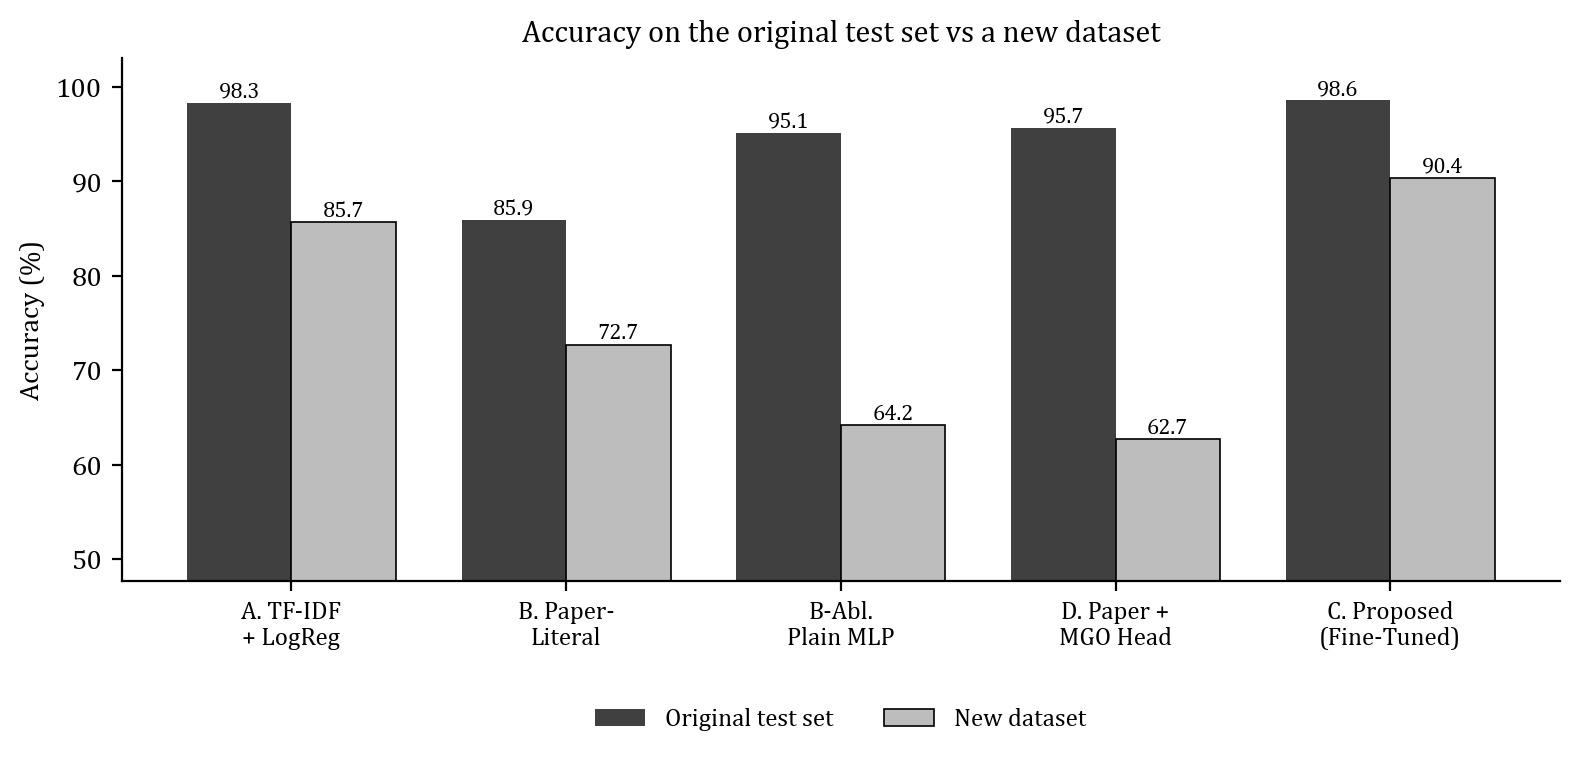

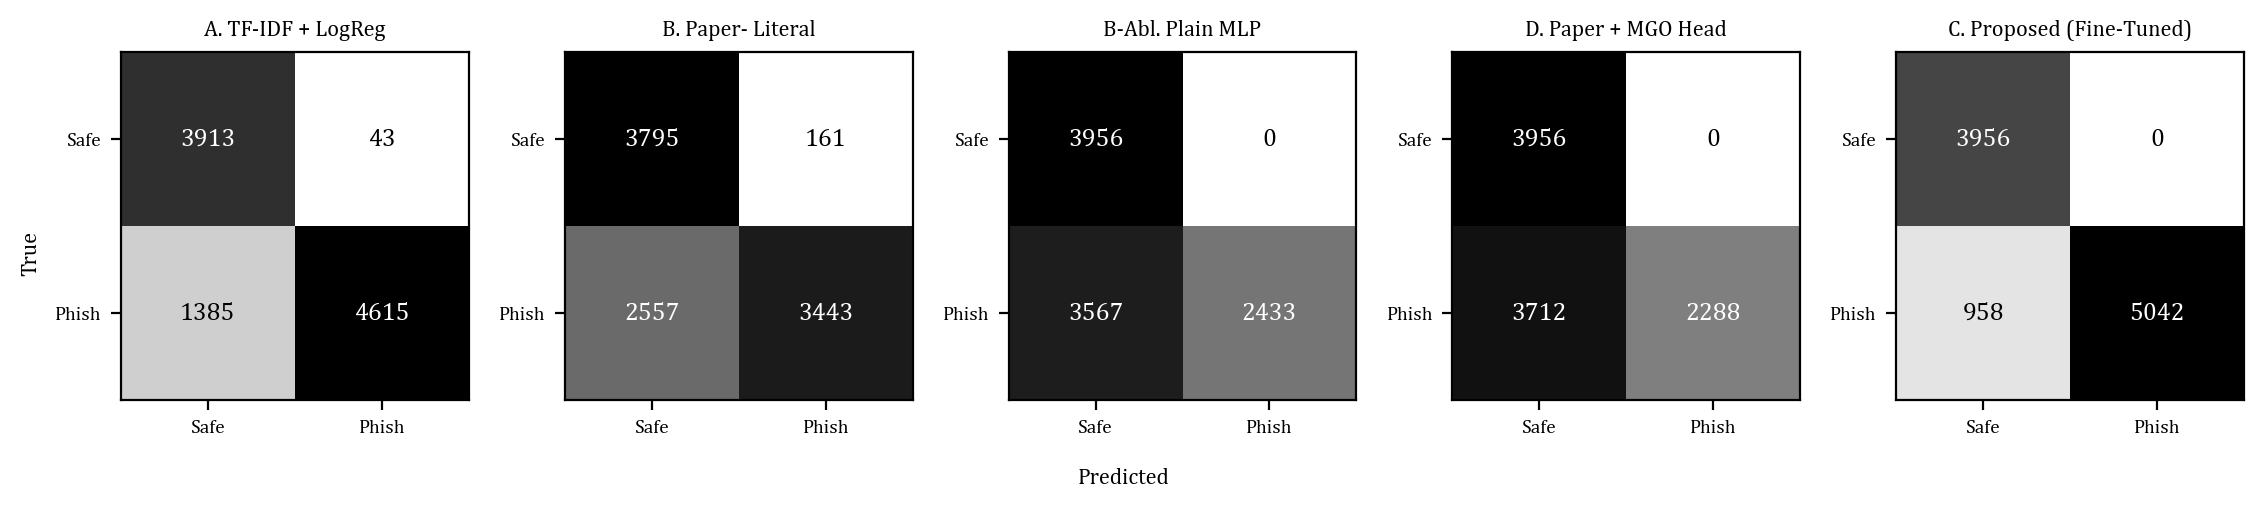

In [16]:
plt.rcParams.update({"font.family": "serif", "font.serif": ["Cambria", "Caladea", "DejaVu Serif"]})
short = {"A. TF-IDF + Logistic Regression": "A. TF-IDF\n+ LogReg", "B. Paper-Literal Model": "B. Paper-\nLiteral",
         "B-Ablation: Plain MLP": "B-Abl.\nPlain MLP", "D. Paper-Literal + MGO Head": "D. Paper +\nMGO Head",
         "C. Corrected, Fine-Tuned Model": "C. Proposed\n(Fine-Tuned)"}
names = list(P_orig)
o = [RES[(RES.model == n) & (RES.dataset == "Original test")].accuracy.item() * 100 for n in names]
w = [RES[(RES.model == n) & (RES.dataset == "New dataset")].accuracy.item() * 100 for n in names]

x = np.arange(len(names)); bw = 0.38
fig, ax = plt.subplots(figsize=(8, 4), dpi=200)
b1 = ax.bar(x - bw / 2, o, bw, color="#404040", label="Original test set")
b2 = ax.bar(x + bw / 2, w, bw, color="#BDBDBD", edgecolor="black", linewidth=0.6, label="New dataset")
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.6, f"{b.get_height():.1f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([short.get(n, n) for n in names], fontsize=9)
ax.set_ylabel("Accuracy (%)"); ax.set_ylim(max(0, min(o + w) - 15), 103)
ax.set_title("Accuracy on the original test set vs a new dataset", fontsize=11)
ax.legend(frameon=False, fontsize=9, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.2))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "robustness_accuracy.png"), facecolor="white"); plt.show()

fig, axes = plt.subplots(1, len(names), figsize=(2.3 * len(names), 2.4), dpi=200)
for ax, n in zip(np.atleast_1d(axes), names):
    cm = confusion_matrix(y_new, P_new[n] >= .5, labels=[0, 1])
    ax.imshow(cm, cmap="Greys")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=9,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Safe", "Phish"], fontsize=7)
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Safe", "Phish"], fontsize=7)
    ax.set_title(short.get(n, n).replace("\n", " "), fontsize=8)
fig.supxlabel("Predicted", fontsize=8); fig.supylabel("True", fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "robustness_confusion.png"), facecolor="white"); plt.show()

## Step 12: Example mistakes of Model C on the new data

In [17]:
if C_NAME in P_new:
    p = P_new[C_NAME]
    err = np.where((p >= .5).astype(int) != y_new)[0]
    print(f"Model C mistakes: {len(err)} of {len(y_new)}")
    for i in err[np.argsort(-np.abs(p[err] - 0.5))][:6]:
        kind = "MISSED PHISHING" if y_new[i] == 1 else "FALSE ALARM"
        print(f"\n[{kind}] P(phishing) = {p[i]:.3f}\n  {str(X_new[i])[:300]!r}")

Model C mistakes: 958 of 9956

[MISSED PHISHING] P(phishing) = 0.001
  'Hello, we talked about meeting again after the conference. An unexpected situation came up during my business trip. My wallet was stolen at the hotel and payment verification failed. Could you help me with a temporary loan? I will transfer back next week.\n\nKeywords: afghanistan, transfer back, engin'

[MISSED PHISHING] P(phishing) = 0.001
  'Hello, we talked about meeting again after the conference. An unexpected situation came up during my business trip. My wallet was stolen at the hotel and payment verification failed. Could you help me with a temporary loan? I will transfer back next week.\n\nKeywords: conference, charity gala, dublin\n'

[MISSED PHISHING] P(phishing) = 0.001
  'Notice, we talked about meeting again after the conference. An unexpected situation came up during my business trip. My wallet was stolen at the hotel and payment verification failed. Could you help me with a temporary loan? I will tra

In [18]:
summary = {"new_dataset_file": os.path.basename(NEW_PATH), "text_col": TEXT_COL, "label_col": LABEL_COL,
           "overlap": OVERLAP, "length_shift": LEN.to_dict("records")}
json.dump(summary, open(os.path.join(OUT, "robustness_summary.json"), "w"), indent=2)
print("Saved to", OUT); print(sorted(os.listdir(OUT)))

Saved to s:\ML-CAPSTONE\robustness_outputs
['length_shift.csv', 'new_dataset_predictions.csv', 'robustness_accuracy.png', 'robustness_by_type.csv', 'robustness_confusion.png', 'robustness_drop.csv', 'robustness_mcnemar.csv', 'robustness_results.csv', 'robustness_summary.json', 'robustness_threshold.csv']
